# Week 11 - Quora: Text Processing, Advanced Features & Visual EDA

**Topics (record sections g, h)**
* g. Text cleaning and pair-level features (common words, Jaccard similarity)
* h. Visualising the features

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/quora/train.csv")

df = df.dropna(subset=["is_duplicate"]).copy()
df["question1"] = df["question1"].fillna("")
df["question2"] = df["question2"].fillna("")
df["is_duplicate"] = df["is_duplicate"].astype(int)

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["is_duplicate"])

# simple length features used by the plots in section h
df["q1_length"] = df["question1"].str.len()
df["q2_length"] = df["question2"].str.len()
print("Train/test:", train_df.shape, test_df.shape)

Train/test: (323420, 6) (80856, 6)


## g. Text pre-processing
`clean_text` does three things:
1. lower-case (`"How"` and `"how"` become the same word),
2. replace everything except letters, digits and whitespace with a space (removes punctuation, `?`, `$`...),
3. squeeze multiple spaces into one.

`pair_features` builds numbers describing the **relationship between the two questions**:
* `common_words` = number of distinct words in both questions,
* `jaccard_similarity` = shared words / all distinct words = $\frac{|A\cap B|}{|A\cup B|}$ (0 = nothing in common, 1 = same word set).

Example before running on 400k rows:

In [2]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

q1, q2 = "How do I learn Python quickly?", "What is the fastest way to learn Python?"
print("Cleaned Q1:", clean_text(q1))
print("Cleaned Q2:", clean_text(q2))

Cleaned Q1: how do i learn python quickly
Cleaned Q2: what is the fastest way to learn python


In [3]:
def pair_features(q1, q2):
    words1 = set(clean_text(q1).split())
    words2 = set(clean_text(q2).split())
    common = len(words1 & words2)
    total = len(words1 | words2)
    return {
        "q1_length": len(str(q1)),
        "q2_length": len(str(q2)),
        "length_difference": abs(len(str(q1)) - len(str(q2))),
        "common_words": common,
        "jaccard_similarity": common / total if total else 0,
    }

print(pair_features(q1, q2))

{'q1_length': 30, 'q2_length': 40, 'length_difference': 10, 'common_words': 2, 'jaccard_similarity': 0.16666666666666666}


Apply the cleaning to every question in the train and test sets (this takes a little while on 400k pairs):

In [4]:
train_df = train_df.copy()
test_df = test_df.copy()
train_df["question1_clean"] = train_df["question1"].apply(clean_text)
train_df["question2_clean"] = train_df["question2"].apply(clean_text)
test_df["question1_clean"] = test_df["question1"].apply(clean_text)
test_df["question2_clean"] = test_df["question2"].apply(clean_text)

display(train_df[["question1_clean", "question2_clean", "is_duplicate"]].head())

,question1_clean,question2_clean,is_duplicate
268624,my dell inspiron 15r 5537 make noice tuck tuck...,i was set up on a date unknowingly i ve always...,0
385786,why is bill gates net worth still rising when ...,how come bill gates is still the richest man i...,1
257720,how do bernie sanders and donald trump differ ...,what are the differences between the global tr...,1
324425,what s the meaning of life,what is the meaning of life to you,1
269584,what is the best open source php form builder ...,what are the ways to insert an image path into...,0


In [5]:
# The record builds a DataFrame from a list of pd.Series, which is slow; returning plain dicts gives the same table much faster.
train_pair_features = pd.DataFrame([pair_features(a, b) for a, b in zip(train_df["question1"], train_df["question2"])])
test_pair_features = pd.DataFrame([pair_features(a, b) for a, b in zip(test_df["question1"], test_df["question2"])])

display(train_pair_features.head())
print("Train features:", train_pair_features.shape, "| Test features:", test_pair_features.shape)

,q1_length,q2_length,length_difference,common_words,jaccard_similarity
0,69,148,79,2,0.057143
1,72,168,96,9,0.264706
2,55,94,39,6,0.333333
3,27,35,8,5,0.555556
4,143,141,2,8,0.190476


Train features: (323420, 5) | Test features: (80856, 5)


## h. Feature analysis and visualisation
### Class balance

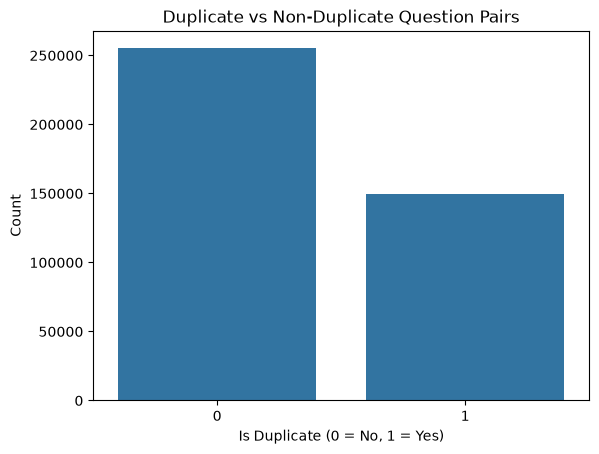

In [6]:
sns.countplot(data=df, x="is_duplicate")
plt.title("Duplicate vs Non-Duplicate Question Pairs")
plt.xlabel("Is Duplicate (0 = No, 1 = Yes)"); plt.ylabel("Count"); plt.show()

### Question length by class
The box shows the middle 50% of values, the line inside is the median; dots are outliers.

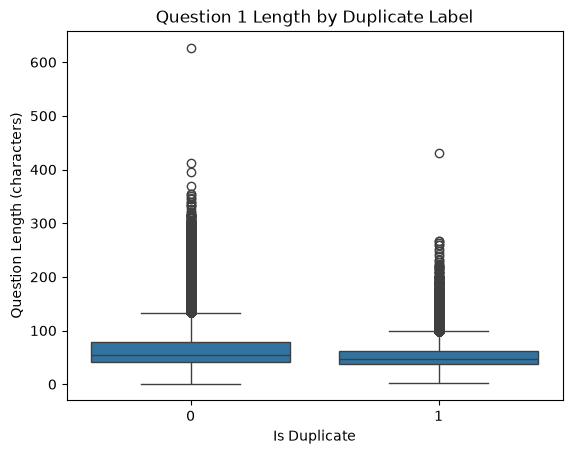

In [7]:
sns.boxplot(data=df, x="is_duplicate", y="q1_length")
plt.title("Question 1 Length by Duplicate Label")
plt.xlabel("Is Duplicate"); plt.ylabel("Question Length (characters)"); plt.show()

### Do the new pair features separate the classes?
Jaccard similarity and the number of shared words should be **higher for duplicates**. Plot their distributions per class (on the training set).

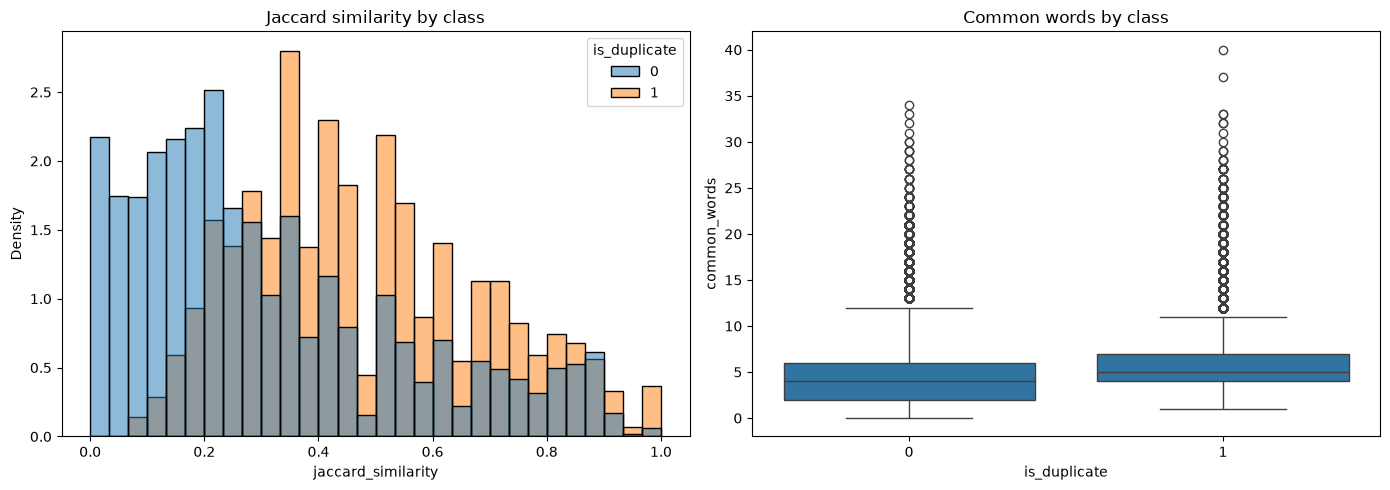

              common_words  jaccard_similarity  length_difference
is_duplicate                                                     
0                    4.529               0.307             24.337
1                    5.860               0.472             13.169


In [8]:
plot_df = train_pair_features.copy()
plot_df["is_duplicate"] = train_df["is_duplicate"].values

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=plot_df, x="jaccard_similarity", hue="is_duplicate", bins=30, stat="density", common_norm=False, ax=axs[0])
axs[0].set_title("Jaccard similarity by class")
sns.boxplot(data=plot_df, x="is_duplicate", y="common_words", ax=axs[1])
axs[1].set_title("Common words by class")
plt.tight_layout(); plt.show()

print(plot_df.groupby("is_duplicate")[["common_words", "jaccard_similarity", "length_difference"]].mean().round(3))

**Reading it:** duplicates share clearly more words (higher Jaccard) and differ less in length. These hand-made features alone already carry signal; Week 12 adds TF-IDF text vectors for much more.

## Summary
* Cleaned all questions and built pair features (length difference, common words, Jaccard).
* Visual EDA confirmed these features discriminate duplicates from non-duplicates.